# Brain Tumor MRI Classification — VGG16 (20 Epochs)


Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


67/67 - 647s - 10s/step - accuracy: 0.7701 - loss: 0.5311 - val_accuracy: 0.8799 - val_loss: 0.3116
Epoch 2/20
67/67 - 639s - 10s/step - accuracy: 0.8671 - loss: 0.3157 - val_accuracy: 0.9061 - val_loss: 0.2816
Epoch 3/20
67/67 - 651s - 10s/step - accuracy: 0.8960 - loss: 0.2520 - val_accuracy: 0.9017 - val_loss: 0.2594
Epoch 4/20
67/67 - 658s - 10s/step - accuracy: 0.9263 - loss: 0.1928 - val_accuracy: 0.9083 - val_loss: 0.2388
Epoch 5/20
67/67 - 659s - 10s/step - accuracy: 0.9370 - loss: 0.1653 - val_accuracy: 0.9083 - val_loss: 0.2213
Epoch 6/20
67/67 - 662s - 10s/step - accuracy: 0.9352 - loss: 0.1589 - val_accuracy: 0.8996 - val_loss: 0.2175
Epoch 7/20
67/67 - 664s - 10s/step - accuracy: 0.9510 - loss: 0.1324 - val_accuracy: 0.9279 - val_loss: 0.2049
Epoch 8/20
67/67 - 658s - 10s/step - accuracy: 0.9646 - loss: 0.1061 - val_accuracy: 0.9258 - val_loss: 0.2015
Epoch 9/20
67/67 - 657s - 10s/step - accuracy: 0.9496 - loss: 0.1242 - val_accuracy: 0.9236 - val_loss: 0.2001
Epoch 10/20


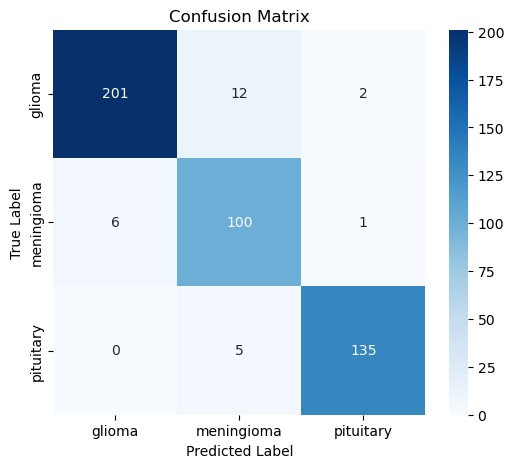

ValueError: y should be a 1d array, got an array of shape (462, 3) instead.

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Flatten
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_curve, auc, confusion_matrix, classification_report
import seaborn as sns
import os

# Base data directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'

# Paths
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# ImageDataGenerator
datagen = ImageDataGenerator(rescale=1./255)

train_data = datagen.flow_from_directory(train_dir, target_size=(img_height, img_width),
                                         batch_size=batch_size, class_mode='categorical', shuffle=True)
val_data = datagen.flow_from_directory(val_dir, target_size=(img_height, img_width),
                                       batch_size=batch_size, class_mode='categorical', shuffle=True)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

# Load VGG16 base model
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False  # freeze layers

# Build model on top
x = base_model.output
x = Flatten()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# Compile model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train model
history = model.fit(train_data, epochs=20, validation_data=val_data, callbacks=[early_stopping], verbose=2)

# Evaluate on test set
test_loss, test_acc = model.evaluate(test_data)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predictions
test_labels = test_data.classes
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & classification report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=test_data.class_indices.keys()))

# Confusion matrix plot
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.class_indices.keys(),
            yticklabels=test_data.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Precision-Recall Curve (for class index 2)
precision, recall, _ = precision_recall_curve(test_labels == 2, test_preds == 2)
pr_auc = auc(recall, precision)
print(f"🔢 Precision-Recall AUC for class 2: {pr_auc:.2f}")

plt.figure()
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {pr_auc:.2f})', color='green')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(test_labels == 2, test_preds == 2)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Accuracy & Loss curves
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [2]:
model.save('VGG16 model_20 Epochs.h5')  # Save the model
print("Model saved successfully!")

Model saved successfully!


In [2]:
import time
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === PATHS ===
model_path = r"C:\Users\usER\Downloads\VGG16 model_20 Epochs.h5"
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\glioma\3061.jpg"

# === Load Model ===
model = load_model(model_path)
print("✅ Model loaded successfully.")

# === Load and Preprocess Image ===
img = load_img(image_path, target_size=(224, 224))  # adjust to your model input
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)  # shape: (1, 224, 224, 3)

# === Measure Inference Time ===
start = time.time()
_ = model.predict(img_array)
end = time.time()

inference_time_ms = (end - start) * 1000
print(f"🕒 Inference Time: {inference_time_ms:.2f} ms")

# === Measure Model Size ===
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"💾 Model Size: {model_size_mb:.2f} MB")


✅ Model loaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
🕒 Inference Time: 1616.64 ms
💾 Model Size: 203.25 MB


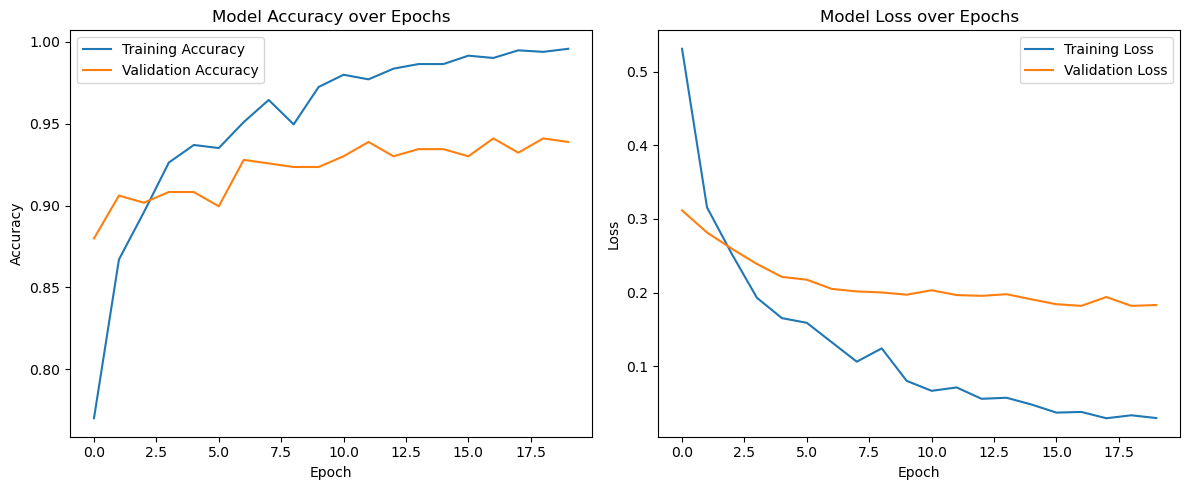

In [6]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()



Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 131s 9s/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.93      0.95       215
  meningioma       0.85      0.93      0.89       107
   pituitary       0.98      0.96      0.97       140

    accuracy                           0.94       462
   macro avg       0.93      0.94      0.94       462
weighted avg       0.95      0.94      0.94       462



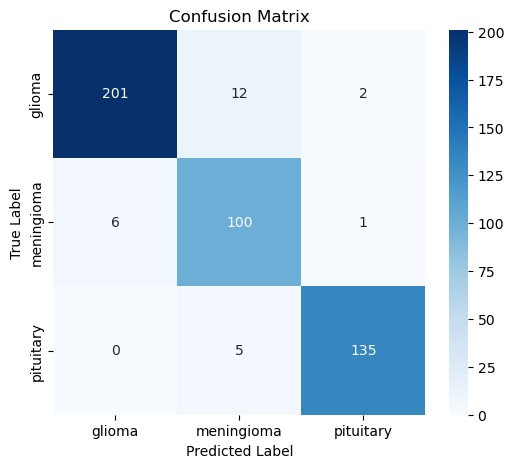

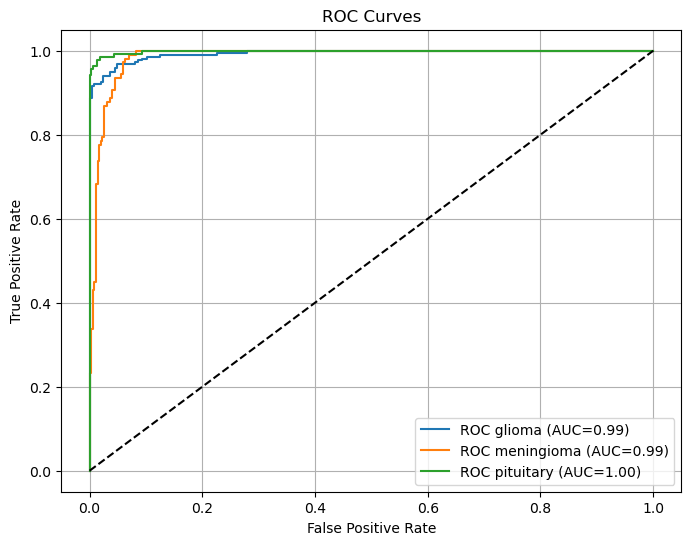

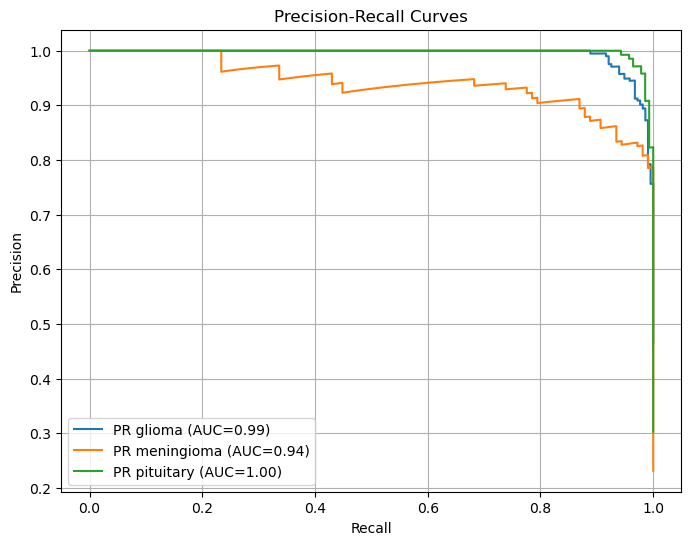

In [5]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load model
model = load_model('VGG16 model_20 Epochs.h5')

# Data setup
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')
img_height, img_width = 224, 224
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

test_labels = test_data.classes
class_names = list(test_data.class_indices.keys())
n_classes = len(class_names)

# Predictions
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & report (optional)
from sklearn.metrics import confusion_matrix, classification_report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=class_names))

# Plot Confusion Matrix (optional)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Binarize labels for multi-class metrics
y_true_bin = label_binarize(test_labels, classes=range(n_classes))

# ROC Curve and AUC per class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC {class_names[i]} (AUC={roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve and AUC per class
precision = dict()
recall = dict()
pr_auc = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], test_preds[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f'PR {class_names[i]} (AUC={pr_auc[i]:.2f})')
plt.title('Precision-Recall Curves')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()


TensorFlow version: 2.17.0

No GPU detected. Training will use CPU.

CHECKING DATASET
Training directory: OK
Validation directory: OK
Test directory: OK

Loading training data...
Found 2144 images belonging to 3 classes.

Loading validation data...
Found 458 images belonging to 3 classes.

Loading test data...
Found 462 images belonging to 3 classes.

DATASET INFORMATION
Training images: 2144
Validation images: 458
Test images: 462
Number of classes: 3

Class mapping:
0: glioma
1: meningioma
2: pituitary

LOADING VGG16


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,561,795 (105.14 MB)

 Trainable params: 12,847,107 (49.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)


STARTING TRAINING
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: val_loss improved from inf to 0.33840, saving model to C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_TB_best.keras
67/67 - 694s - 10s/step - accuracy: 0.7453 - loss: 0.6265 - val_accuracy: 0.8624 - val_loss: 0.3384
Epoch 2/20

Epoch 2: val_loss did not improve from 0.33840
67/67 - 733s - 11s/step - accuracy: 0.8764 - loss: 0.3151 - val_accuracy: 0.8428 - val_loss: 0.3533
Epoch 3/20

Epoch 3: val_loss improved from 0.33840 to 0.25784, saving model to C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_TB_best.keras
67/67 - 733s - 11s/step - accuracy: 0.8913 - loss: 0.2610 - val_accuracy: 0.8952 - val_loss: 0.2578
Epoch 4/20

Epoch 4: val_loss improved from 0.25784 to 0.25490, saving model to C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_TB_best.keras
67/67 - 691s - 10s/step - accuracy: 0.9160 - loss: 0.2155 - val_accuracy: 0.8974 - val_loss: 0.2549
Epoch 5/20

Epoch 5: val_loss improved from 0.25490 to 0.23499, saving model to C:\Users\us

Best model loaded successfully.

SAVING H5 MODEL
H5 model saved successfully:
C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_TB_Classification.h5

Class mapping saved:
C:\Users\usER\Downloads\1512427\converted_images_split\class_names.json

MODEL SIZE
Model size: 203.25 MB
Model size: 0.1985 GB
Total parameters: 27,561,795

TEST EVALUATION
15/15 ━━━━━━━━━━━━━━━━━━━━ 116s 8s/step - accuracy: 0.9361 - loss: 0.1764

Test Accuracy: 94.16%
Test Loss: 0.1693

GENERATING PREDICTIONS
15/15 ━━━━━━━━━━━━━━━━━━━━ 120s 8s/step

Prediction shape: (462, 3)
True labels shape: (462,)

INFERENCE TIME
Test images: 462
Total inference time: 120.3236 seconds
Average inference time: 260.44 ms/image
Inference speed: 3.84 images/second

CONFUSION MATRIX
[[197  17   1]
 [  2 105   0]
 [  0   7 133]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9899    0.9163    0.9517       215
  meningioma     0.8140    0.9813    0.8898       107
   pituitary 

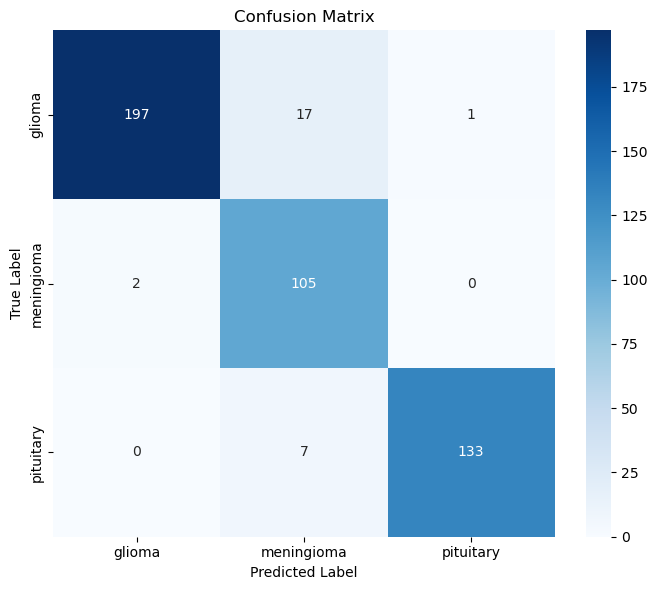


SENSITIVITY AND SPECIFICITY

Class: glioma
TP: 197
TN: 245
FP: 2
FN: 18
Sensitivity: 91.63%
Specificity: 99.19%

Class: meningioma
TP: 105
TN: 331
FP: 24
FN: 2
Sensitivity: 98.13%
Specificity: 93.24%

Class: pituitary
TP: 133
TN: 321
FP: 1
FN: 7
Sensitivity: 95.00%
Specificity: 99.69%

MACRO-AVERAGE
Mean Sensitivity: 94.92%
Mean Specificity: 97.37%

PRECISION-RECALL AUC
glioma PR AUC: 0.9918
meningioma PR AUC: 0.9355
pituitary PR AUC: 0.9970


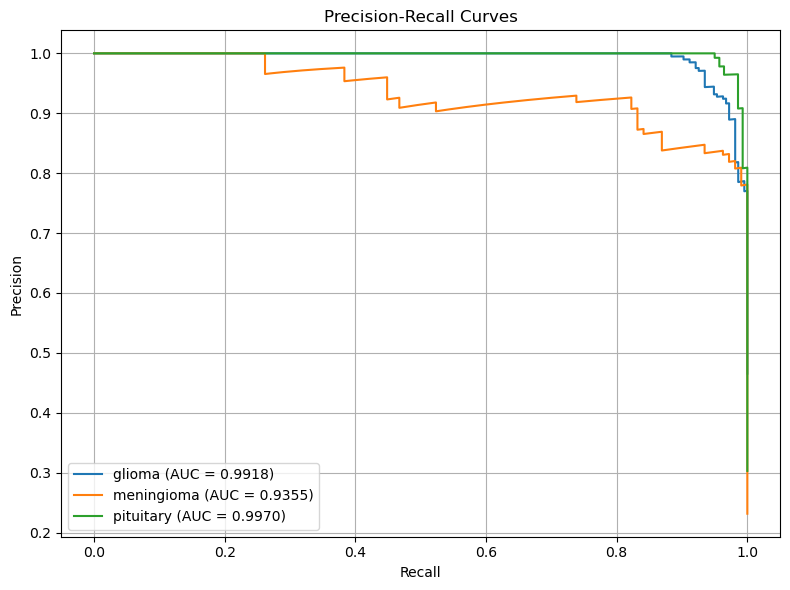


ROC AUC
glioma ROC AUC: 0.9919
meningioma ROC AUC: 0.9838
pituitary ROC AUC: 0.9985


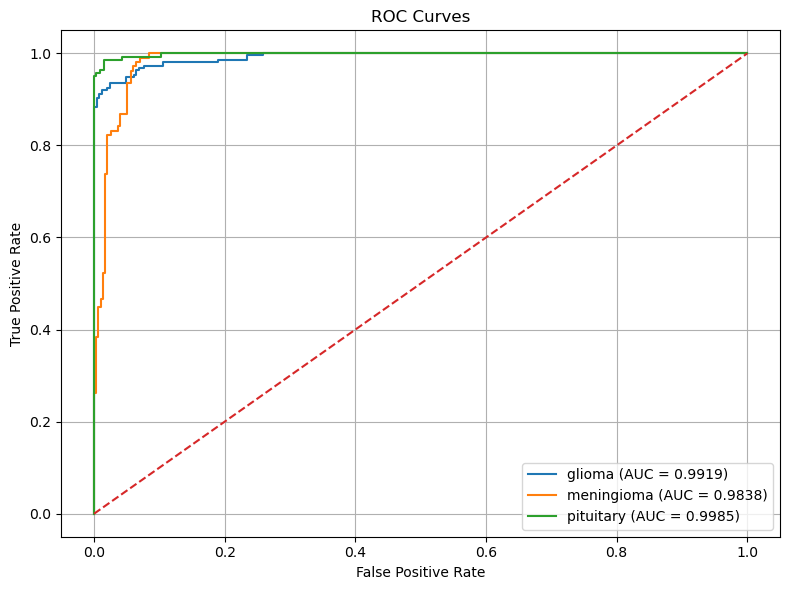

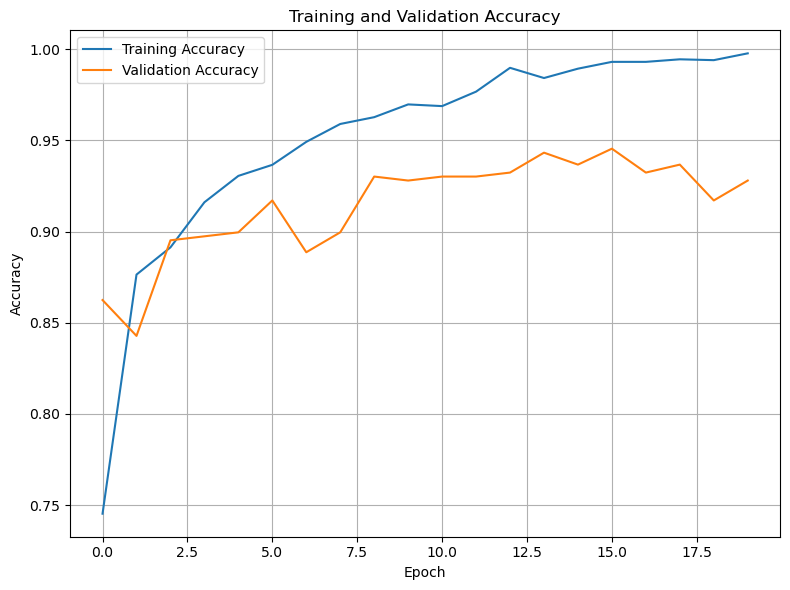

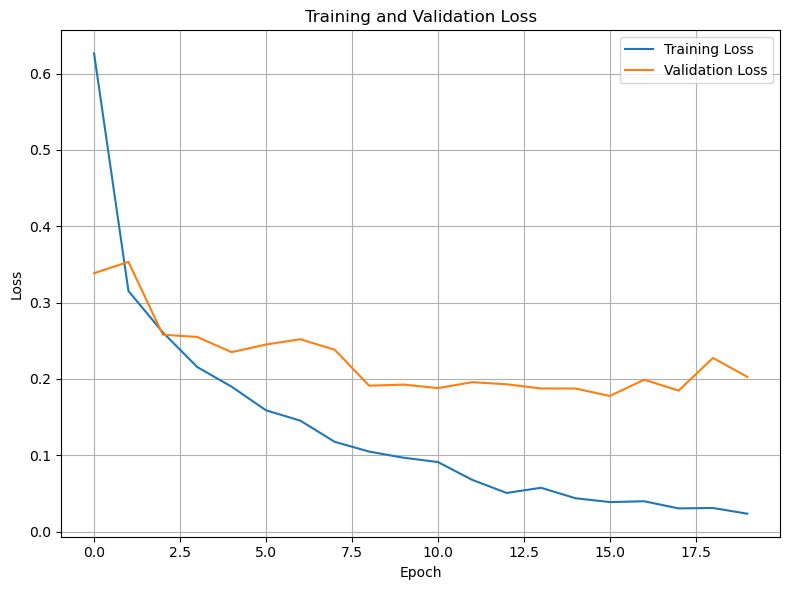



                  FINAL MODEL RESULTS

Test Accuracy: 94.16%
Test Loss: 0.1693
Mean Sensitivity: 94.92%
Mean Specificity: 97.37%
Mean PR AUC: 0.9748
Mean ROC AUC: 0.9914
Average Inference Time: 260.44 ms/image
Inference Speed: 3.84 images/second
Model Size: 203.25 MB
Total Parameters: 27,561,795

Best H5 Model:
C:\Users\usER\Downloads\1512427\converted_images_split\VGG16_TB_Classification.h5

Class Mapping:
{'glioma': 0, 'meningioma': 1, 'pituitary': 2}

TRAINING AND EVALUATION COMPLETED SUCCESSFULLY


In [4]:
# ============================================================
# VGG16 TRANSFER LEARNING
# 3-CLASS BRAIN TUMOR CLASSIFICATION
#
# Classes:
# 0 = glioma
# 1 = meningioma
# 2 = pituitary
#
# Includes:
# - Training
# - Validation
# - Best model checkpoint
# - H5 model saving
# - Accuracy
# - Loss
# - Confusion Matrix
# - Classification Report
# - Sensitivity
# - Specificity
# - Precision-Recall AUC
# - ROC AUC
# - Inference Time
# - Model Size
# - Parameter Count
# - Training Curves
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report
)


# ============================================================
# 2. TENSORFLOW INFORMATION
# ============================================================

print("TensorFlow version:", tf.__version__)


# ============================================================
# 3. CHECK GPU
# ============================================================

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("\nGPU detected:")
    for gpu in gpus:
        print(gpu)
else:
    print("\nNo GPU detected. Training will use CPU.")


# ============================================================
# 4. BASE DATA DIRECTORY
# ============================================================

base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'


# ============================================================
# 5. DATASET DIRECTORIES
# ============================================================

train_dir = os.path.join(
    base_dir,
    'train'
)

val_dir = os.path.join(
    base_dir,
    'val'
)

test_dir = os.path.join(
    base_dir,
    'test'
)


# ============================================================
# 6. CHECK DIRECTORIES
# ============================================================

print("\n========================================")
print("CHECKING DATASET")
print("========================================")

if not os.path.exists(train_dir):
    raise FileNotFoundError(
        f"Training directory not found:\n{train_dir}"
    )

if not os.path.exists(val_dir):
    raise FileNotFoundError(
        f"Validation directory not found:\n{val_dir}"
    )

if not os.path.exists(test_dir):
    raise FileNotFoundError(
        f"Test directory not found:\n{test_dir}"
    )

print("Training directory: OK")
print("Validation directory: OK")
print("Test directory: OK")


# ============================================================
# 7. IMAGE PARAMETERS
# ============================================================

img_height = 224
img_width = 224
batch_size = 32
epochs = 20


# ============================================================
# 8. IMAGE DATA GENERATOR
# ============================================================

datagen = ImageDataGenerator(
    rescale=1.0 / 255
)


# ============================================================
# 9. LOAD TRAINING DATA
# ============================================================

print("\nLoading training data...")

train_data = datagen.flow_from_directory(
    train_dir,
    target_size=(
        img_height,
        img_width
    ),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)


# ============================================================
# 10. LOAD VALIDATION DATA
# ============================================================

print("\nLoading validation data...")

val_data = datagen.flow_from_directory(
    val_dir,
    target_size=(
        img_height,
        img_width
    ),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


# ============================================================
# 11. LOAD TEST DATA
# ============================================================

print("\nLoading test data...")

test_data = datagen.flow_from_directory(
    test_dir,
    target_size=(
        img_height,
        img_width
    ),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


# ============================================================
# 12. CLASS INFORMATION
# ============================================================

num_classes = len(
    train_data.class_indices
)

class_indices = train_data.class_indices

class_names = list(
    class_indices.keys()
)


print("\n========================================")
print("DATASET INFORMATION")
print("========================================")

print(
    "Training images:",
    train_data.samples
)

print(
    "Validation images:",
    val_data.samples
)

print(
    "Test images:",
    test_data.samples
)

print(
    "Number of classes:",
    num_classes
)

print("\nClass mapping:")

for class_name, class_index in class_indices.items():

    print(
        f"{class_index}: {class_name}"
    )


# ============================================================
# 13. VERIFY CLASS MAPPING
# ============================================================

if train_data.class_indices != val_data.class_indices:

    raise ValueError(
        "Training and validation class mappings are different."
    )


if train_data.class_indices != test_data.class_indices:

    raise ValueError(
        "Training and test class mappings are different."
    )


# ============================================================
# 14. LOAD VGG16
# ============================================================

print("\n========================================")
print("LOADING VGG16")
print("========================================")

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(
        img_height,
        img_width,
        3
    )
)


# ============================================================
# 15. FREEZE VGG16
# ============================================================

base_model.trainable = False


# ============================================================
# 16. BUILD MODEL
# ============================================================

x = base_model.output

x = Flatten()(x)

x = Dense(
    512,
    activation='relu'
)(x)

x = Dropout(
    0.5
)(x)

output = Dense(
    num_classes,
    activation='softmax'
)(x)


# ============================================================
# 17. CREATE MODEL
# ============================================================

model = Model(
    inputs=base_model.input,
    outputs=output
)


# ============================================================
# 18. MODEL SUMMARY
# ============================================================

model.summary()


# ============================================================
# 19. COMPILE MODEL
# ============================================================

model.compile(
    optimizer=Adam(
        learning_rate=0.0001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# ============================================================
# 20. EARLY STOPPING
# ============================================================

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)


# ============================================================
# 21. CHECKPOINT PATH
#
# IMPORTANT:
# Keras 3 requires .keras for ModelCheckpoint
# ============================================================

checkpoint_path = os.path.join(
    base_dir,
    'VGG16_TB_best.keras'
)


# ============================================================
# 22. FINAL H5 MODEL PATH
# ============================================================

h5_model_path = os.path.join(
    base_dir,
    'VGG16_TB_Classification.h5'
)


# ============================================================
# 23. MODEL CHECKPOINT
# ============================================================

checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)


# ============================================================
# 24. START TRAINING
# ============================================================

print("\n========================================")
print("STARTING TRAINING")
print("========================================")

training_start_time = time.perf_counter()


history = model.fit(
    train_data,
    epochs=epochs,
    validation_data=val_data,
    callbacks=[
        early_stopping,
        checkpoint
    ],
    verbose=2
)


training_end_time = time.perf_counter()


# ============================================================
# 25. TRAINING TIME
# ============================================================

total_training_time = (
    training_end_time -
    training_start_time
)


print("\n========================================")
print("TRAINING COMPLETED")
print("========================================")

print(
    f"Total training time: "
    f"{total_training_time:.2f} seconds"
)

print(
    f"Total training time: "
    f"{total_training_time / 60:.2f} minutes"
)


# ============================================================
# 26. LOAD BEST MODEL
# ============================================================

print("\n========================================")
print("LOADING BEST MODEL")
print("========================================")

best_model = tf.keras.models.load_model(
    checkpoint_path
)

print(
    "Best model loaded successfully."
)


# ============================================================
# 27. SAVE BEST MODEL AS H5
# ============================================================

print("\n========================================")
print("SAVING H5 MODEL")
print("========================================")

best_model.save(
    h5_model_path
)

print(
    "H5 model saved successfully:"
)

print(
    h5_model_path
)


# ============================================================
# 28. SAVE CLASS MAPPING
# ============================================================

class_names_path = os.path.join(
    base_dir,
    'class_names.json'
)


with open(
    class_names_path,
    'w'
) as f:

    json.dump(
        class_indices,
        f,
        indent=4
    )


print(
    "\nClass mapping saved:"
)

print(
    class_names_path
)


# ============================================================
# 29. MODEL SIZE
# ============================================================

model_size_bytes = os.path.getsize(
    h5_model_path
)

model_size_mb = (
    model_size_bytes /
    (1024 ** 2)
)

model_size_gb = (
    model_size_bytes /
    (1024 ** 3)
)


print("\n========================================")
print("MODEL SIZE")
print("========================================")

print(
    f"Model size: "
    f"{model_size_mb:.2f} MB"
)

print(
    f"Model size: "
    f"{model_size_gb:.4f} GB"
)

print(
    f"Total parameters: "
    f"{best_model.count_params():,}"
)


# ============================================================
# 30. EVALUATE TEST SET
# ============================================================

print("\n========================================")
print("TEST EVALUATION")
print("========================================")

test_data.reset()


test_loss, test_accuracy = (
    best_model.evaluate(
        test_data,
        verbose=1
    )
)


print(
    f"\nTest Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Test Loss: "
    f"{test_loss:.4f}"
)


# ============================================================
# 31. GENERATE TEST PREDICTIONS
# ============================================================

print("\n========================================")
print("GENERATING PREDICTIONS")
print("========================================")


test_data.reset()


inference_start_time = time.perf_counter()


test_preds = best_model.predict(
    test_data,
    verbose=1
)


inference_end_time = time.perf_counter()


# True labels
test_labels = test_data.classes


# Predicted labels
test_preds_labels = np.argmax(
    test_preds,
    axis=1
)


print(
    "\nPrediction shape:",
    test_preds.shape
)

print(
    "True labels shape:",
    test_labels.shape
)


# ============================================================
# 32. INFERENCE TIME
# ============================================================

total_inference_time = (
    inference_end_time -
    inference_start_time
)


num_test_images = test_data.samples


average_inference_time = (
    total_inference_time /
    num_test_images
)


images_per_second = (
    num_test_images /
    total_inference_time
)


print("\n========================================")
print("INFERENCE TIME")
print("========================================")

print(
    f"Test images: "
    f"{num_test_images}"
)

print(
    f"Total inference time: "
    f"{total_inference_time:.4f} seconds"
)

print(
    f"Average inference time: "
    f"{average_inference_time * 1000:.2f} ms/image"
)

print(
    f"Inference speed: "
    f"{images_per_second:.2f} images/second"
)


# ============================================================
# 33. CONFUSION MATRIX
# ============================================================

conf_matrix = confusion_matrix(
    test_labels,
    test_preds_labels
)


print("\n========================================")
print("CONFUSION MATRIX")
print("========================================")

print(
    conf_matrix
)


# ============================================================
# 34. CLASSIFICATION REPORT
# ============================================================

print("\n========================================")
print("CLASSIFICATION REPORT")
print("========================================")


print(
    classification_report(
        test_labels,
        test_preds_labels,
        target_names=class_names,
        digits=4
    )
)


# ============================================================
# 35. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(
    figsize=(7, 6)
)


sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.title(
    'Confusion Matrix'
)

plt.xlabel(
    'Predicted Label'
)

plt.ylabel(
    'True Label'
)

plt.tight_layout()

plt.show()


# ============================================================
# 36. SENSITIVITY AND SPECIFICITY
# ============================================================

print("\n========================================")
print("SENSITIVITY AND SPECIFICITY")
print("========================================")


sensitivity_list = []

specificity_list = []


for class_index in range(
    num_classes
):

    # ----------------------------------------
    # TRUE BINARY LABELS
    # ----------------------------------------

    y_true_binary = (
        test_labels == class_index
    ).astype(int)


    # ----------------------------------------
    # PREDICTED BINARY LABELS
    # ----------------------------------------

    y_pred_binary = (
        test_preds_labels == class_index
    ).astype(int)


    # ----------------------------------------
    # ONE-VS-REST CONFUSION MATRIX
    # ----------------------------------------

    cm = confusion_matrix(
        y_true_binary,
        y_pred_binary,
        labels=[0, 1]
    )


    tn, fp, fn, tp = cm.ravel()


    # ----------------------------------------
    # SENSITIVITY
    # ----------------------------------------

    if (
        tp + fn
    ) > 0:

        sensitivity = (
            tp /
            (tp + fn)
        )

    else:

        sensitivity = 0.0


    # ----------------------------------------
    # SPECIFICITY
    # ----------------------------------------

    if (
        tn + fp
    ) > 0:

        specificity = (
            tn /
            (tn + fp)
        )

    else:

        specificity = 0.0


    sensitivity_list.append(
        sensitivity
    )

    specificity_list.append(
        specificity
    )


    print(
        f"\nClass: "
        f"{class_names[class_index]}"
    )

    print(
        f"TP: {tp}"
    )

    print(
        f"TN: {tn}"
    )

    print(
        f"FP: {fp}"
    )

    print(
        f"FN: {fn}"
    )

    print(
        f"Sensitivity: "
        f"{sensitivity * 100:.2f}%"
    )

    print(
        f"Specificity: "
        f"{specificity * 100:.2f}%"
    )


# ============================================================
# 37. MACRO AVERAGE
# ============================================================

mean_sensitivity = np.mean(
    sensitivity_list
)

mean_specificity = np.mean(
    specificity_list
)


print("\n========================================")
print("MACRO-AVERAGE")
print("========================================")

print(
    f"Mean Sensitivity: "
    f"{mean_sensitivity * 100:.2f}%"
)

print(
    f"Mean Specificity: "
    f"{mean_specificity * 100:.2f}%"
)


# ============================================================
# 38. PRECISION-RECALL CURVES
# ============================================================

print("\n========================================")
print("PRECISION-RECALL AUC")
print("========================================")


pr_auc_list = []


plt.figure(
    figsize=(8, 6)
)


for class_index in range(
    num_classes
):

    # Binary true labels
    y_true_binary = (
        test_labels == class_index
    ).astype(int)


    # IMPORTANT:
    # Use probability of ONLY this class
    y_score = test_preds[
        :,
        class_index
    ]


    precision, recall, _ = (
        precision_recall_curve(
            y_true_binary,
            y_score
        )
    )


    pr_auc = auc(
        recall,
        precision
    )


    pr_auc_list.append(
        pr_auc
    )


    print(
        f"{class_names[class_index]} "
        f"PR AUC: "
        f"{pr_auc:.4f}"
    )


    plt.plot(
        recall,
        precision,
        label=(
            f"{class_names[class_index]} "
            f"(AUC = {pr_auc:.4f})"
        )
    )


plt.xlabel(
    'Recall'
)

plt.ylabel(
    'Precision'
)

plt.title(
    'Precision-Recall Curves'
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 39. ROC CURVES
# ============================================================

print("\n========================================")
print("ROC AUC")
print("========================================")


roc_auc_list = []


plt.figure(
    figsize=(8, 6)
)


for class_index in range(
    num_classes
):

    # Binary true labels
    y_true_binary = (
        test_labels == class_index
    ).astype(int)


    # Probability for current class
    y_score = test_preds[
        :,
        class_index
    ]


    fpr, tpr, _ = roc_curve(
        y_true_binary,
        y_score
    )


    roc_auc = auc(
        fpr,
        tpr
    )


    roc_auc_list.append(
        roc_auc
    )


    print(
        f"{class_names[class_index]} "
        f"ROC AUC: "
        f"{roc_auc:.4f}"
    )


    plt.plot(
        fpr,
        tpr,
        label=(
            f"{class_names[class_index]} "
            f"(AUC = {roc_auc:.4f})"
        )
    )


# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)


plt.xlabel(
    'False Positive Rate'
)

plt.ylabel(
    'True Positive Rate'
)

plt.title(
    'ROC Curves'
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 40. TRAINING ACCURACY CURVE
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)


plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)


plt.title(
    'Training and Validation Accuracy'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Accuracy'
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 41. TRAINING LOSS CURVE
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.plot(
    history.history['loss'],
    label='Training Loss'
)


plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)


plt.title(
    'Training and Validation Loss'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Loss'
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 42. MEAN AUC VALUES
# ============================================================

mean_pr_auc = np.mean(
    pr_auc_list
)

mean_roc_auc = np.mean(
    roc_auc_list
)


# ============================================================
# 43. FINAL RESULTS
# ============================================================

print("\n")
print("============================================================")
print("                  FINAL MODEL RESULTS")
print("============================================================")


print(
    f"\nTest Accuracy:"
    f" {test_accuracy * 100:.2f}%"
)


print(
    f"Test Loss:"
    f" {test_loss:.4f}"
)


print(
    f"Mean Sensitivity:"
    f" {mean_sensitivity * 100:.2f}%"
)


print(
    f"Mean Specificity:"
    f" {mean_specificity * 100:.2f}%"
)


print(
    f"Mean PR AUC:"
    f" {mean_pr_auc:.4f}"
)


print(
    f"Mean ROC AUC:"
    f" {mean_roc_auc:.4f}"
)


print(
    f"Average Inference Time:"
    f" {average_inference_time * 1000:.2f} ms/image"
)


print(
    f"Inference Speed:"
    f" {images_per_second:.2f} images/second"
)


print(
    f"Model Size:"
    f" {model_size_mb:.2f} MB"
)


print(
    f"Total Parameters:"
    f" {best_model.count_params():,}"
)


print(
    "\nBest H5 Model:"
)

print(
    h5_model_path
)


print(
    "\nClass Mapping:"
)

print(
    class_indices
)


print(
    "\n============================================================"
)

print(
    "TRAINING AND EVALUATION COMPLETED SUCCESSFULLY"
)

print(
    "============================================================"
)